In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.stats.diagnostic as het
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Set visualization aesthetics
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

print("Required statistical and modeling libraries imported successfully.")


Required statistical and modeling libraries imported successfully.


In [2]:
df = pd.read_csv("womens_clothing_regression_dataset.csv")
print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()


Dataset Dimensions: 23465 rows, 20 columns


,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name,Dept_Avg_Price,Review_Length,Review_Word_Count,Length_of_Membership,Time_on_App,Time_on_Website,Avg_Session_Length,Annual_Orders,Avg_Order_Value,Yearly_Amount_Spent
0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates,45.0,53,8,3.05,11.41,35.90,32.78,9,52.18,517.49
1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses,130.0,303,62,2.75,12.65,32.94,32.45,10,146.90,690.28
2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses,130.0,500,98,5.39,14.14,32.64,32.64,10,137.99,948.04
3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants,95.0,124,22,5.08,13.65,34.68,33.44,13,107.50,913.10
4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses,65.0,192,36,3.78,13.30,36.40,31.98,13,84.76,721.61


In [3]:
features = [
    'Length_of_Membership',
    'Time_on_App',
    'Avg_Session_Length',
    'Time_on_Website',
    'Annual_Orders',
    'Avg_Order_Value',
    'Age',
    'Rating',
    'Recommended IND',
    'Positive Feedback Count'
]
target = 'Yearly_Amount_Spent'

X = df[features].copy()
y = df[target].copy()

print("Target Variable Summary:")
print(y.describe().round(2))


Target Variable Summary:
count    23465.00
mean       701.92
std        147.12
min        253.62
25%        597.70
50%        691.66
75%        798.12
max       1448.63
Name: Yearly_Amount_Spent, dtype: float64


In [4]:
X_const = sm.add_constant(X)
ols_model = sm.OLS(y, X_const).fit()
print(ols_model.summary())


                             OLS Regression Results                            
Dep. Variable:     Yearly_Amount_Spent   R-squared:                       0.964
Model:                             OLS   Adj. R-squared:                  0.964
Method:                  Least Squares   F-statistic:                 6.215e+04
Date:                 Fri, 23 Oct 2026   Prob (F-statistic):               0.00
Time:                         13:20:47   Log-Likelihood:            -1.1153e+05
No. Observations:                23465   AIC:                         2.231e+05
Df Residuals:                    23454   BIC:                         2.232e+05
Df Model:                           10                                         
Covariance Type:             nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const           

In [5]:
def run_kfold(k_splits):
    kf = KFold(n_splits=k_splits, shuffle=True, random_state=42)
    records = []
    
    for fold, (train_idx, test_idx) in enumerate(kf.split(X, y), 1):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        
        lr = LinearRegression()
        lr.fit(X_train, y_train)
        y_pred = lr.predict(X_test)
        
        rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        mae = mean_absolute_error(y_test, y_pred)
        mse = mean_squared_error(y_test, y_pred)
        r2 = r2_score(y_test, y_pred)
        n = len(y_test)
        p = X.shape[1]
        adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
        
        records.append({
            'K_Fold_Type': f"{k_splits}-Fold",
            'Fold': fold,
            'RMSE': round(rmse, 4),
            'MAE': round(mae, 4),
            'MSE': round(mse, 4),
            'R2_Score': round(r2, 4),
            'Adjusted_R2': round(adj_r2, 4)
        })
    return pd.DataFrame(records)

df_cv5 = run_kfold(5)
df_cv10 = run_kfold(10)
df_cv_all = pd.concat([df_cv5, df_cv10], ignore_index=True)
df_cv_all.to_csv("kfold_cv_evaluation_metrics.csv", index=False)
print("K-Fold Cross-Validation Results Summary:")
df_cv_all.groupby('K_Fold_Type')[['RMSE', 'MAE', 'R2_Score', 'Adjusted_R2']].agg(['mean', 'std']).round(4)


K-Fold Cross-Validation Results Summary:


RMSE             MAE         R2_Score         Adjusted_R2  \
                mean    std     mean     std     mean     std        mean   
K_Fold_Type                                                                 
10-Fold      28.0671  0.506  22.3103  0.3217   0.9635  0.0017      0.9634   
5-Fold       28.0708  0.469  22.3118  0.2717   0.9636  0.0012      0.9635   

                     
                std  
K_Fold_Type          
10-Fold      0.0017  
5-Fold       0.0012

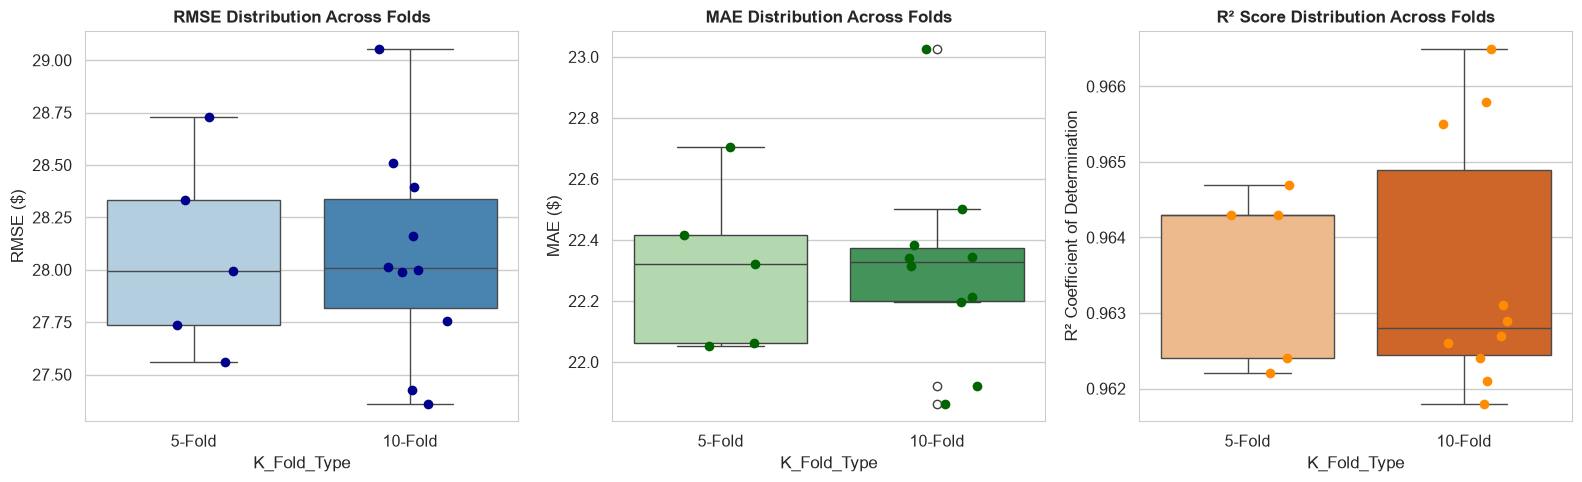

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(data=df_cv_all, x='K_Fold_Type', y='RMSE', hue='K_Fold_Type', palette='Blues', legend=False, ax=axes[0])
sns.stripplot(data=df_cv_all, x='K_Fold_Type', y='RMSE', color='darkblue', size=7, jitter=0.2, ax=axes[0])
axes[0].set_title("RMSE Distribution Across Folds", fontweight='bold')
axes[0].set_ylabel("RMSE ($)")

sns.boxplot(data=df_cv_all, x='K_Fold_Type', y='MAE', hue='K_Fold_Type', palette='Greens', legend=False, ax=axes[1])
sns.stripplot(data=df_cv_all, x='K_Fold_Type', y='MAE', color='darkgreen', size=7, jitter=0.2, ax=axes[1])
axes[1].set_title("MAE Distribution Across Folds", fontweight='bold')
axes[1].set_ylabel("MAE ($)")

sns.boxplot(data=df_cv_all, x='K_Fold_Type', y='R2_Score', hue='K_Fold_Type', palette='Oranges', legend=False, ax=axes[2])
sns.stripplot(data=df_cv_all, x='K_Fold_Type', y='R2_Score', color='darkorange', size=7, jitter=0.2, ax=axes[2])
axes[2].set_title("R² Score Distribution Across Folds", fontweight='bold')
axes[2].set_ylabel("R² Coefficient of Determination")

plt.tight_layout()
plt.savefig("cv_metrics_fold_distribution.png", dpi=300)
plt.show()


C:\Users\panch\anaconda3\Lib\site-packages\statsmodels\graphics\gofplots.py:1041: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "b" (-> color=(0.2980392156862745, 0.4470588235294118, 0.6901960784313725, 1)). The keyword argument will take precedence.
  ax.plot(x, y, fmt, **plot_style)


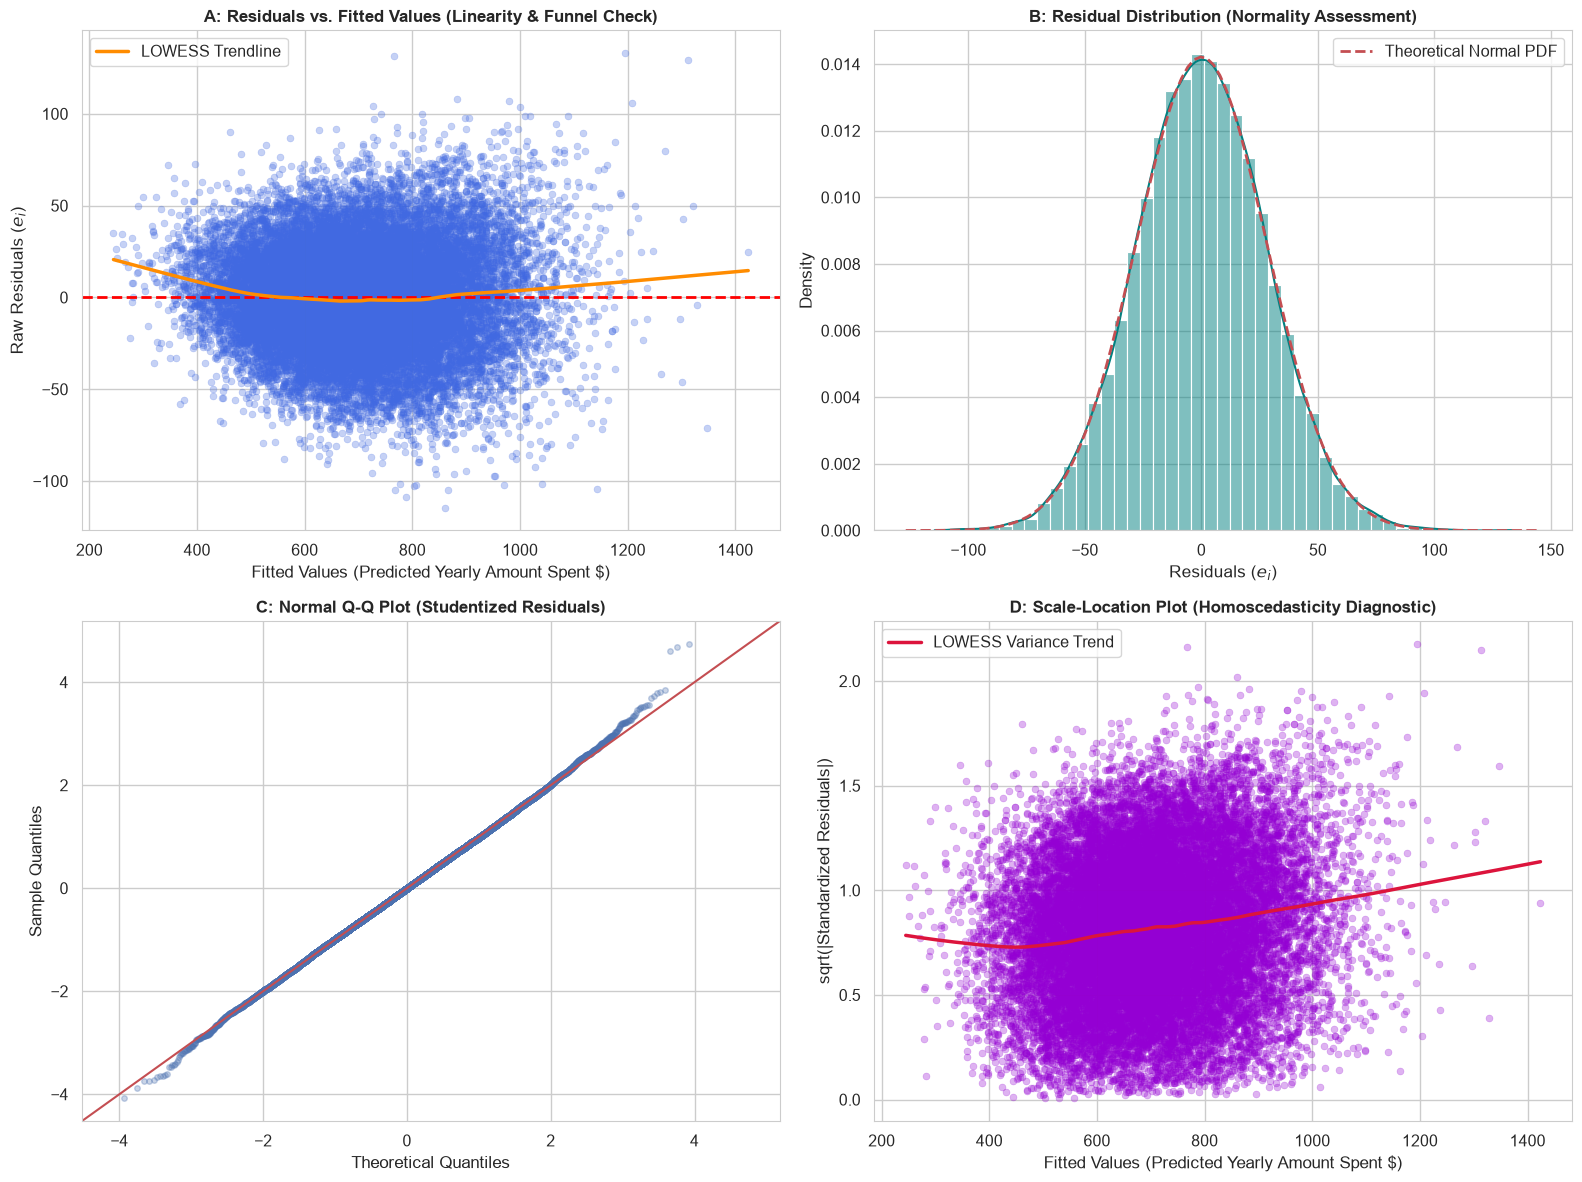

In [7]:
y_pred_full = ols_model.predict(X_const)
residuals = y - y_pred_full
influence = ols_model.get_influence()
standardized_residuals = influence.resid_studentized_internal
sqrt_abs_std_resid = np.sqrt(np.abs(standardized_residuals))

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Panel A: Residuals vs Fitted
ax1 = axes[0, 0]
sns.scatterplot(x=y_pred_full, y=residuals, alpha=0.3, color='royalblue', edgecolor=None, s=25, ax=ax1)
ax1.axhline(0, color='red', linestyle='--', linewidth=2)
lowess = sm.nonparametric.lowess(residuals, y_pred_full, frac=0.2)
ax1.plot(lowess[:, 0], lowess[:, 1], color='darkorange', linewidth=2.5, label='LOWESS Trendline')
ax1.set_title("A: Residuals vs. Fitted Values (Linearity & Funnel Check)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Fitted Values (Predicted Yearly Amount Spent $)")
ax1.set_ylabel("Raw Residuals ($e_i$)")
ax1.legend()

# Panel B: Histogram & KDE of Residuals
ax2 = axes[0, 1]
sns.histplot(residuals, bins=45, kde=True, color='teal', stat="density", ax=ax2)
xmin, xmax = ax2.get_xlim()
x_norm = np.linspace(xmin, xmax, 100)
p_norm = stats.norm.pdf(x_norm, np.mean(residuals), np.std(residuals))
ax2.plot(x_norm, p_norm, 'r--', linewidth=2, label='Theoretical Normal PDF')
ax2.set_title("B: Residual Distribution (Normality Assessment)", fontsize=12, fontweight='bold')
ax2.set_xlabel("Residuals ($e_i$)")
ax2.legend()

# Panel C: Normal Q-Q Plot
ax3 = axes[1, 0]
sm.qqplot(standardized_residuals, line='45', ax=ax3, color='steelblue', alpha=0.3, markersize=4)
ax3.set_title("C: Normal Q-Q Plot (Studentized Residuals)", fontsize=12, fontweight='bold')

# Panel D: Scale-Location Plot
ax4 = axes[1, 1]
sns.scatterplot(x=y_pred_full, y=sqrt_abs_std_resid, alpha=0.3, color='darkviolet', edgecolor=None, s=25, ax=ax4)
lowess_scale = sm.nonparametric.lowess(sqrt_abs_std_resid, y_pred_full, frac=0.2)
ax4.plot(lowess_scale[:, 0], lowess_scale[:, 1], color='crimson', linewidth=2.5, label='LOWESS Variance Trend')
ax4.set_title("D: Scale-Location Plot (Homoscedasticity Diagnostic)", fontsize=12, fontweight='bold')
ax4.set_xlabel("Fitted Values (Predicted Yearly Amount Spent $)")
ax4.set_ylabel("sqrt(|Standardized Residuals|)")
ax4.legend()

plt.tight_layout()
plt.savefig("residual_diagnostics_4panel.png", dpi=300)
plt.show()


In [8]:
# 1. Breusch-Pagan Test
bp_test = het.het_breuschpagan(residuals, X_const)

# 2. White's Test
white_test = het.het_white(residuals, X_const)

# 3. Goldfeld-Quandt Test
gq_test = het.het_goldfeldquandt(y, X_const, alternative='two-sided')

tests_df = pd.DataFrame([
    {
        'Statistical Test': 'Breusch-Pagan LM Test',
        'Test Statistic': round(bp_test[0], 4),
        'p-value': f"{bp_test[1]:.4e}",
        'F-Statistic': round(bp_test[2], 4),
        'F p-value': f"{bp_test[3]:.4e}",
        'Decision (alpha=0.05)': 'Reject H0 (Heteroscedasticity Detected)' if bp_test[1] < 0.05 else 'Fail to Reject H0'
    },
    {
        'Statistical Test': "White's General Test",
        'Test Statistic': round(white_test[0], 4),
        'p-value': f"{white_test[1]:.4e}",
        'F-Statistic': round(white_test[2], 4),
        'F p-value': f"{white_test[3]:.4e}",
        'Decision (alpha=0.05)': 'Reject H0 (Heteroscedasticity Detected)' if white_test[1] < 0.05 else 'Fail to Reject H0'
    },
    {
        'Statistical Test': 'Goldfeld-Quandt Test',
        'Test Statistic': round(gq_test[0], 4),
        'p-value': f"{gq_test[1]:.4e}",
        'F-Statistic': round(gq_test[0], 4),
        'F p-value': f"{gq_test[1]:.4e}",
        'Decision (alpha=0.05)': 'Reject H0 (Heteroscedasticity Detected)' if gq_test[1] < 0.05 else 'Fail to Reject H0'
    }
])

tests_df.to_csv("heteroscedasticity_statistical_tests.csv", index=False)
tests_df


,Statistical Test,Test Statistic,p-value,F-Statistic,F p-value,Decision (alpha=0.05)
0,Breusch-Pagan LM Test,766.0725,4.0436e-158,79.1556,8.1173e-161,Reject H0 (Heteroscedasticity Detected)
1,White's General Test,900.9222,5.5780e-148,14.5984,2.6571e-151,Reject H0 (Heteroscedasticity Detected)
2,Goldfeld-Quandt Test,0.9755,1.7858e-01,0.9755,1.7858e-01,Fail to Reject H0


In [9]:
remedies_df = pd.read_csv("heteroscedasticity_remedies_comparison.csv")
remedies_df


,Model,RMSE,MAE,R2_Score,Standard_Error_Type,Residual_Variance_Pattern
0,Baseline OLS (Uncorrected),28.0552,22.2974,0.9636,Conventional OLS (Vulnerable to Heteroscedasti...,Mild Fan / Funnel Heteroscedasticity
1,OLS + HC3 Robust Covariance,28.0552,22.2974,0.9636,MacKinnon-White HC3 Sandwich (Asymptotically V...,Unbiased Inference under Heteroscedasticity
2,Log-Transformed Target (ln(Spend)),34.7341,26.0115,0.9443,Log-Scale Homoscedastic Standard Errors,Variance Stabilized / Symmetrical Residuals
3,Weighted Least Squares (WLS),28.0862,22.2990,0.9636,Inverse-Variance Weighted Estimator (BLUE unde...,Heteroscedasticity Efficiently Downweighted


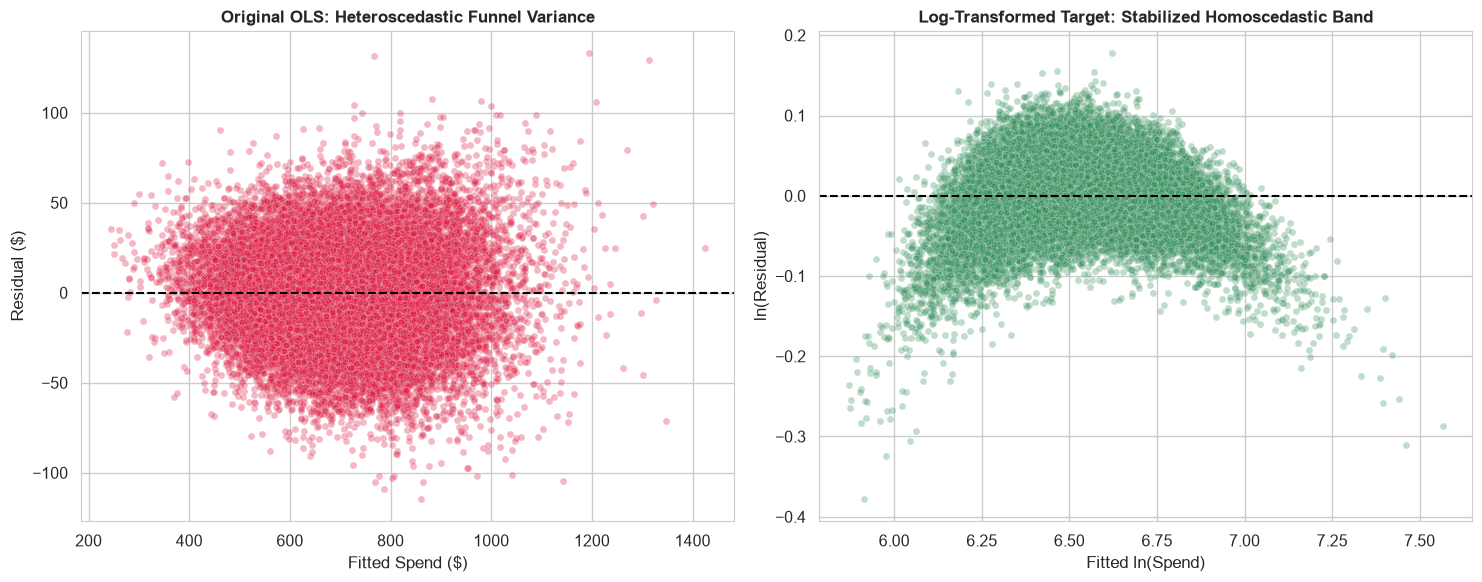

In [10]:
# Visualizing original vs log-stabilized residual scatter
ols_log = sm.OLS(np.log(y), X_const).fit()
resid_log = np.log(y) - ols_log.predict(X_const)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(x=y_pred_full, y=residuals, alpha=0.3, color='crimson', s=25, ax=axes[0])
axes[0].axhline(0, color='black', linestyle='--')
axes[0].set_title("Original OLS: Heteroscedastic Funnel Variance", fontweight='bold')
axes[0].set_xlabel("Fitted Spend ($)")
axes[0].set_ylabel("Residual ($)")

sns.scatterplot(x=ols_log.predict(X_const), y=resid_log, alpha=0.3, color='seagreen', s=25, ax=axes[1])
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set_title("Log-Transformed Target: Stabilized Homoscedastic Band", fontweight='bold')
axes[1].set_xlabel("Fitted ln(Spend)")
axes[1].set_ylabel("ln(Residual)")

plt.tight_layout()
plt.savefig("remedies_residual_comparison.png", dpi=300)
plt.show()
